# Lecture 13, The Coupled Model Intercomparison Project: history and design

> Where the climate projections used in hydrology come from

Lectures 4 to 6 built small climate models, and Lectures 9 to 12 built the numerical machinery that larger models use (advection, diffusion, grids, time stepping). The projections that appear in the IPCC reports, in national climate assessments and in most climate-impact studies for catchments, however, do not come from one model. They come from an **intercomparison**: many modelling centres run the *same* experiments with *different* models, and the results are archived in a common format. The project that organizes this is the **Coupled Model Intercomparison Project (CMIP)**.

This lecture and the next are conceptual. They explain what CMIP is, how it has changed from CMIP1 to CMIP6, how an experiment is designed and named, and (in Lecture 14) how scenarios, climate sensitivity and uncertainty work and what is new in **CMIP7**. Lecture 15 then analyses real model output with `xarray`.

By the end of this lecture you should be able to

- explain why a multi-model ensemble is used instead of a single "best" model,
- describe how each CMIP phase differed from the one before it,
- name the four DECK experiments and the historical simulation and say what each is for,
- read a CMIP6 file identifier such as `CESM2 / ssp245 / r1i1p1f1 / Amon / pr`,
- explain why raw CMIP output cannot simply be dropped into a catchment model.


In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# 1) Why intercompare models?

A **coupled climate model** is a computer model in which the main parts of the climate system (atmosphere, ocean, land surface, sea ice, and in newer models also vegetation, the carbon cycle and aerosols) are solved together and exchange heat, water and momentum, as sketched in Lecture 2. The energy balance model of Lecture 4 is the simplest member of this family. The models used in CMIP solve the equations of fluid motion on a three-dimensional grid and are run on supercomputers.

No such model is correct. Each represents unresolved processes (clouds, convection, soil moisture, vegetation) with approximations, and different centres make different choices. If every centre ran its own experiment with its own forcing, a difference between two results could come from the model *or* from the set-up, and nobody could tell which. CMIP removes the second possibility. The modelling centres agree on

- a **common set of experiments** with the same forcing (for example, "quadruple CO$_2$ abruptly"),
- a **common output format and variable naming**, so that results from dozens of models can be processed by the same program, and
- a **common archive** from which anyone can download the results.

The stated objective of CMIP is to better understand past, present and future climate changes arising from natural, unforced variability or in response to changes in radiative forcing, **in a multi-model context**. That means two things: assessing how well the models perform in the historical period, and quantifying the *causes of the spread* between models in future projections. The spread between models is itself a measure of how uncertain the science is, which is why the ensemble matters more than any one member.

```{note} CMIP and the IPCC
CMIP is organized by the World Climate Research Programme (WCRP), not by the IPCC. The two are linked in time: the IPCC assessment reports are built on the CMIP archives that were available when the authors wrote them (CMIP3 for the Fourth Assessment Report, 2007; CMIP5 for the Fifth, 2013; CMIP6 for the Sixth, 2021).
```


# 2) From CMIP1 to CMIP6

CMIP has run in phases since the mid-1990s. Each phase was prompted by new scientific questions, by models that had grown more complex, and by computers that had grown much faster. The table summarizes how the design changed. (The numbers are typical or approximate. Resolution varied between models within a phase.)

| Phase | Started | Defining experiments | Typical atmospheric grid spacing | What was new |
|:--|:--|:--|:--|:--|
| **CMIP1** | 1995 | Unforced control runs from 21 coupled atmosphere&ndash;ocean(&ndash;ice) models | ~500 km | First archive of coupled models. About half used *flux adjustment*, an artificial correction at the air&ndash;sea interface that kept the model from drifting. |
| **CMIP2** | 1997 | Idealized forcing: CO$_2$ rising by 1 % per year (a linear increase in radiative forcing), from 17 of the CMIP1 models | coarse | The first *forced* experiment, and the first multi-decade to multi-century runs. |
| **CMIP3** | 2005&ndash;06 | Twentieth-century and 21st-century runs under the **SRES** emission scenarios; used for the IPCC Fourth Assessment | ~200 km | A genuine *multi-model ensemble* for projections, widely opened to the research community. Aerosol effects and the ocean were better represented. |
| **CMIP5** | ~2010&ndash;11 | **Earth System Models** with an interactive carbon cycle; **RCP** scenarios; decadal prediction; IPCC Fifth Assessment | ~100&ndash;200 km | Biogeochemistry, land-use change and a richer set of experiments. |
| **CMIP6** | 2016&ndash; | A permanent core (the **DECK** and the historical run) plus 21 endorsed thematic MIPs; **SSP** scenarios; IPCC Sixth Assessment | ~100 km typical, ~25 km in HighResMIP | A federated structure with common standards. Some models at 0.25&deg; resolution. |

```{note} There is no CMIP4
Phase numbers were chosen to line up with the IPCC cycles, so the numbering jumps from CMIP3 to CMIP5.
```

### What drove the changes

Three pressures recur from phase to phase:

1. **New scientific questions.** Early phases asked how a model's climate and its response to CO$_2$ compared. Later phases asked about the carbon cycle, aerosols, land use, clouds, monsoons, extremes and the human dimension of scenarios.
2. **Faster computers.** Each generation could afford finer grids, more processes and more simulated years (CMIP6 requested of the order of 40 000 additional simulation years from the endorsed MIPs alone).
3. **Demand for regional information.** Policy makers, water managers and farmers need numbers at the scale of a river basin or a district, not a hemisphere. Section 6 returns to this.

### Why resolution matters to a hydrologist

A model grid cell is a single number for temperature, rainfall, soil moisture and so on. The coarser the grid, the smaller the number of independent values over the region you care about. The cell below counts how many grid cells cover India at each of the resolutions in the table, and how many cover a hypothetical 5 000 km$^2$ mountain catchment.

In [3]:
area_india = 3.287e6        # km2, approximate area of India
area_basin = 5000.0         # km2, a hypothetical mountain catchment

print(f"{'grid spacing':>13} {'cells over India':>18} {'cells in basin':>16}")
for name, dx in [("CMIP1  ~500 km", 500), ("CMIP3  ~200 km", 200), ("CMIP6  ~100 km", 100), ("HighRes ~25 km", 25)]:
    cell = dx ** 2
    print(f"{name:>13} {area_india / cell:18.0f} {area_basin / cell:16.2f}")

 grid spacing   cells over India   cells in basin
CMIP1  ~500 km                 13             0.02
CMIP3  ~200 km                 82             0.12
CMIP6  ~100 km                329             0.50
HighRes ~25 km               5259             8.00


At 100 km a 5 000 km$^2$ catchment is only about half of **one** grid cell, so the model cannot represent its topography, its rain shadow or its snow line. At 25 km it is about eight cells. This is why high-resolution experiments (HighResMIP), regional downscaling (CORDEX) and the bias-correction and downscaling methods of Lectures 14 and 16&ndash;23 matter so much for hydrology.

# 3) What kind of model takes part?

CMIP models differ in complexity. The rows below form a ladder, and the energy balance model of Lecture 4 is its first rung.

| Type | Components | Example (CMIP6 name, centre) |
|:--|:--|:--|
| **AOGCM**, atmosphere&ndash;ocean general circulation model | Atmosphere, ocean, land surface, sea ice. CO$_2$ is prescribed. | HadGEM3-GC31 (UK Met Office) |
| **ESM**, Earth system model | An AOGCM plus interactive carbon cycle, and often vegetation, aerosols and atmospheric chemistry. CO$_2$ concentration can be *calculated* from emissions. | CESM2 (NCAR, USA); GFDL-ESM4 (NOAA GFDL, USA) |
| **High-resolution configuration** | The same model run on a finer grid for studies of regional detail and extremes. | MPI-ESM1.2 is run at several resolutions (for example `LR` and `HR`) |
| **Regional climate model (RCM)** | A limited-area model driven at its edges by a global model, to add local detail (not itself a CMIP model, but part of the same chain, see CORDEX below). | *e.g.* RCMs in CORDEX South Asia |

India also contributes: the Indian Institute of Tropical Meteorology, Pune, submitted the **IITM-ESM** to CMIP6.

Each model is identified in the archive by a short **source_id** such as `CESM2` or `MPI-ESM1-2-HR`, and a model can appear in several versions and resolutions. When a paper says "we used 20 CMIP6 models" it usually means 20 `source_id`s that had the variables it needed.


# 4) The CMIP6 design: the DECK, the historical run and the endorsed MIPs

By CMIP5 the number of experiments had grown, and every new question added more. For CMIP6 the community re-organised CMIP into three elements (Eyring et al., 2016):

1. **A permanent core**, the **DECK** (Diagnostic, Evaluation and Characterization of Klima) together with the **CMIP historical simulation**. These are the *entry card*: every model that takes part runs them. They change little from phase to phase, so models from different generations can be compared.
2. **Common standards, coordination, infrastructure and documentation**, so that output can be shared and processed automatically.
3. **A set of CMIP6-Endorsed MIPs**, thematic projects that are specific to this phase, build on the DECK and the historical run and address more specialised questions. Participation is optional and depends on each centre's interests.

CMIP6 was framed around three broad questions, set against the Grand Science Challenges of the WCRP:

- How does the Earth system respond to forcing?
- What are the origins and consequences of systematic model biases?
- How can we assess future climate changes given internal climate variability, predictability and uncertainties in scenarios?


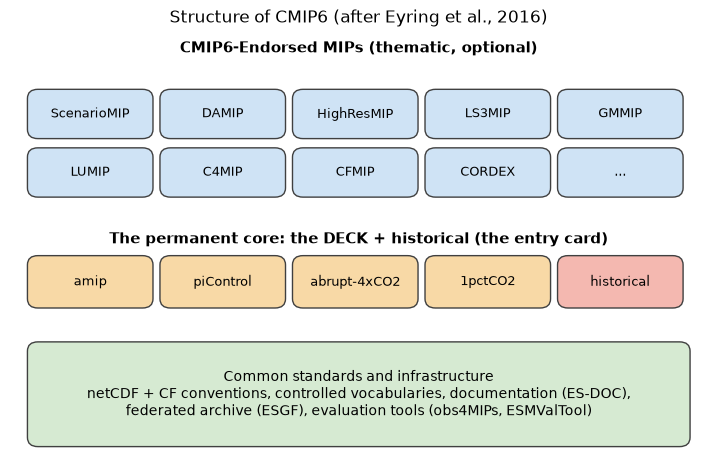

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 7); ax.axis("off")

def box(x, y, w, h, text, fc, fs=10, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                fc=fc, ec="0.25", lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", wrap=True)

# top layer: endorsed MIPs
ax.text(5, 6.65, "CMIP6-Endorsed MIPs (thematic, optional)", ha="center", fontsize=11, fontweight="bold")
mips = ["ScenarioMIP", "DAMIP", "HighResMIP", "LS3MIP", "GMMIP", "LUMIP", "C4MIP", "CFMIP", "CORDEX", "..."]
for k, name in enumerate(mips):
    row, col = divmod(k, 5)
    box(0.3 + col * 1.9, 5.3 - row * 0.95, 1.7, 0.7, name, "#cfe3f5", fs=9)
# middle layer: DECK
ax.text(5, 3.55, "The permanent core: the DECK + historical (the entry card)", ha="center", fontsize=11, fontweight="bold")
for k, name in enumerate(["amip", "piControl", "abrupt-4xCO2", "1pctCO2", "historical"]):
    box(0.3 + k * 1.9, 2.55, 1.7, 0.75, name, "#f8d9a6" if name != "historical" else "#f4b8b0", fs=9)
# bottom layer
box(0.3, 0.3, 9.4, 1.6, "Common standards and infrastructure\nnetCDF + CF conventions, controlled vocabularies, "
    "documentation (ES-DOC),\nfederated archive (ESGF), evaluation tools (obs4MIPs, ESMValTool)", "#d6ead2", fs=10)
ax.set_title("Structure of CMIP6 (after Eyring et al., 2016)")
plt.show()

### The DECK and the historical simulation

| Experiment | What is done | Years | Main purpose |
|:--|:--|:--|:--|
| **`amip`** | Atmosphere (and land) model only, driven by *observed* sea-surface temperature and sea-ice | 1979&ndash;2014 | Evaluate the atmosphere and land components against observations; find out which errors come from there rather than from the ocean |
| **`piControl`** | Fully coupled model with **constant 1850 forcing** | at least 500 | Unforced (internal) variability and model drift; the baseline for all other runs |
| **`abrupt-4xCO2`** | CO$_2$ is quadrupled in one step and then held fixed | at least 150 | Climate sensitivity, feedbacks and fast responses |
| **`1pctCO2`** | CO$_2$ rises by 1 % per year | at least 150 | Idealized benchmark of the transient response, climate sensitivity |
| **`historical`** | Coupled model with the observed forcing: greenhouse gases, aerosols, volcanoes, solar variability, land use | 1850&ndash;2014 | Evaluation against the real climate record |

There are two flavours of each coupled run. In the ordinary version the CO$_2$ concentration is *prescribed*. In the **`esm-`** versions (`esm-piControl`, `esm-hist`), which only Earth system models can run, the CO$_2$ concentration is *calculated* from emissions and the exchange of carbon between the atmosphere, ocean and land.

You have already met two of these in Lecture 4: the "CO$_2$ rising by 1 % per year" run and the "historical" run are the energy balance model's versions of `1pctCO2` and `historical`. `piControl` corresponds to the pre-industrial run in which the temperature relaxed to 14 &deg;C from any starting point. The point of the DECK is that every model, from the one-box model to the most complex Earth system model, can be asked the same questions.


### The CMIP6-Endorsed MIPs

For a MIP to be endorsed it had to address at least one of the three science questions, connect to the DECK and historical runs, follow the CMIP data standards and be supported by enough modelling centres (about eight) to commit to its highest-priority (Tier 1) experiments. Twenty-one MIPs were endorsed. Seventeen of them proposed about 190 experiments, and four were *diagnostic* MIPs that define additional output without new experiments. The table lists the ones most relevant to hydroclimatology.

| MIP | What it is about | Why a hydrologist cares |
|:--|:--|:--|
| **ScenarioMIP** | Future climate under the SSP scenarios (Lecture 14) | The source of nearly all projection studies |
| **DAMIP** | Detection and attribution: how much of the observed change is due to which forcing | Separating human influence from natural variability in observed trends |
| **HighResMIP** | Global models at weather-resolving resolution (~25 km or finer) | Better rainfall, orography and extremes |
| **LS3MIP** | Land surface, snow and soil moisture, and their feedbacks | Soil moisture, snow and evapotranspiration in the models |
| **LUMIP** | Effects of land use on climate and biogeochemistry | Deforestation and irrigation |
| **GMMIP** | Global monsoons | How well the models simulate the Indian monsoon |
| **CFMIP** | Cloud feedbacks | The largest source of spread in climate sensitivity |
| **C4MIP** | Carbon-cycle feedbacks | Link between emissions and warming |
| **CORDEX** (diagnostic) | Regional downscaling of CMIP output | Regional climate inputs for catchment studies |
| **VIACS AB** (diagnostic) | Dialogue with the users: vulnerability, impacts, adaptation and climate services | Fitting the output to what impact studies need |

Other MIPs address aerosols and chemistry (AerChemMIP), decadal prediction (DCPP), the ocean (OMIP), sea ice (SIMIP), ice sheets (ISMIP6), radiative forcing (RFMIP), paleoclimate (PMIP), volcanoes (VolMIP), geoengineering (GeoMIP), ocean heat uptake and sea level (FAFMIP) and atmospheric dynamics (DynVarMIP).


# 5) Standards and the data archive

Dozens of models producing hundreds of variables only form an *ensemble* if the output can be processed automatically. CMIP therefore imposes standards:

- **File format.** Output is stored as **netCDF** files that follow the **CF conventions** for naming, units and coordinates, the format you will open with `xarray` in Lecture 15.
- **Controlled vocabularies.** The names of models, experiments, variables and output frequencies come from agreed lists. Documentation of the models and simulations is collected in a common template (the **ES-DOC** activity).
- **A federated archive.** The model output stays on servers at institutions around the world, and the **Earth System Grid Federation (ESGF)** provides one search and download interface over all of them. A number of cloud copies also exist.
- **Evaluation tools and observations.** Observational datasets are provided in the same format (**obs4MIPs**, **ana4MIPs**), and tools such as **ESMValTool** and the PCMDI metrics package compute standard evaluation diagnostics whenever new output arrives.

### Reading a CMIP6 identifier

Every dataset in the archive has an identifier that records *which model ran which experiment, and what was saved*. The fields below (the example is illustrative) are the vocabulary you need to search the archive and, in Lecture 15, to read files:

| Field | Example | Meaning |
|:--|:--|:--|
| `activity_id` | `ScenarioMIP` | The MIP the experiment belongs to |
| `institution_id` | `NCAR` | The modelling centre |
| `source_id` | `CESM2` | The model |
| `experiment_id` | `ssp245` | The experiment (here SSP2-4.5) |
| `member_id` / variant label | `r1i1p1f1` | The ensemble member (see below) |
| `table_id` | `Amon` | Frequency and realm of output (`Amon` = monthly atmosphere, `Lmon` = monthly land, `day` = daily) |
| `variable_id` | `pr` | The variable (`pr` precipitation, `tas` near-surface air temperature, `evspsbl` evaporation, `mrro` total runoff, `mrso` total soil moisture) |
| `grid_label` | `gn` | Native grid (`gr` = regridded) |

The **variant label** `r<R>i<I>p<P>f<F>` identifies the ensemble member: realization **r** (different initial conditions of the same model), initialization method **i**, physics version **p** and forcing version **f**. Members `r1i1p1f1`, `r2i1p1f1`, `r3i1p1f1` differ only in the starting state, so the differences between them are *internal variability* (Lecture 14).

In [5]:
def parse_cmip6_id(dataset_id):
    fields = ["mip_era", "activity_id", "institution_id", "source_id", "experiment_id",
              "member_id", "table_id", "variable_id", "grid_label", "version"]
    return dict(zip(fields, dataset_id.split(".")))

def parse_variant(label):
    import re
    r, i, p, f = map(int, re.fullmatch(r"r(\d+)i(\d+)p(\d+)f(\d+)", label).groups())
    return {"realization": r, "initialization": i, "physics": p, "forcing": f}

example = "CMIP6.ScenarioMIP.NCAR.CESM2.ssp245.r1i1p1f1.Amon.pr.gn.v20190308"   # illustrative
info = parse_cmip6_id(example)
for k, v in info.items():
    print(f"{k:15} {v}")
print(parse_variant(info["member_id"]))

mip_era         CMIP6
activity_id     ScenarioMIP
institution_id  NCAR
source_id       CESM2
experiment_id   ssp245
member_id       r1i1p1f1
table_id        Amon
variable_id     pr
grid_label      gn
version         v20190308
{'realization': 1, 'initialization': 1, 'physics': 1, 'forcing': 1}


# 6) What this means for a hydrologist

CMIP is the best available source of future climate, but its output has to be used with care.

- **Scale.** A global model is not built to give a rainfall series at your gauge (Section 2). The result is usually *post-processed*: bias-corrected, statistically downscaled, or used to drive a regional climate model (CORDEX). Lecture 14 introduces these steps and Lectures 16&ndash;23 treat them in detail.
- **Which variables.** Hydrology needs precipitation (`pr`), evaporation (`evspsbl`), runoff (`mrro`), soil moisture (`mrso`), snow (`snw`) and temperature (`tas`), usually at daily or monthly resolution. Not every model saved every variable at every frequency.
- **Biases.** Models share systematic errors, for example in the timing and intensity of the Indian monsoon or in drizzle that is too frequent and too light. The `amip` and `historical` runs are how those errors are found (Section 4).
- **Spread is information.** Use several models, not one. The range between them is an estimate of the uncertainty that the project is designed to expose.
- **Stationarity.** A design based on the observed record assumes the climate of the past represents the future. CMIP projections are the evidence that it does not (Lecture 2).

## Summary

- CMIP organises many modelling centres to run the *same* experiments so that differences between results can be attributed to the models.
- Phases CMIP1 to CMIP6 added forcing experiments, scenarios, Earth system components, thematic MIPs and common standards, at ever finer resolution.
- CMIP6 is built on the **DECK** (`amip`, `piControl`, `abrupt-4xCO2`, `1pctCO2`) plus the **historical** run, with endorsed MIPs on top and shared data standards underneath.
- A CMIP6 dataset is identified by model, experiment, **variant label**, table and variable.
- For catchment work the global output must be downscaled and bias-corrected (Lectures 16&ndash;23). **Lecture 14** covers scenarios, climate sensitivity, uncertainty and CMIP7.

## Check your understanding

1. Why is the `piControl` run needed even though it simulates a world that never existed?
2. Which DECK experiment would you use to find out whether an error in simulated monsoon rainfall comes from the atmosphere or from the ocean? Why?
3. Two runs of CESM2 have variant labels `r1i1p1f1` and `r2i1p1f1`. What is different between them, and what can you learn from comparing them?
4. A 5 000 km$^2$ catchment lies inside one grid cell of a 100 km model. List two reasons why the model's rainfall for that cell should not be used directly in a rainfall&ndash;runoff model.


```{note} Sources
Written for **CE524 Applied Hydroclimatology**, adapting the course slides *Changes in Modeling and Simulation Patterns from CMIP1 to CMIP6* and the CMIP6 overview paper below.

**Main reference.**
Eyring, V., Bony, S., Meehl, G. A., Senior, C. A., Stevens, B., Stouffer, R. J., & Taylor, K. E. (2016). Overview of the Coupled Model Intercomparison Project Phase 6 (CMIP6) experimental design and organization. *Geoscientific Model Development, 9*, 1937&ndash;1958. [doi:10.5194/gmd-9-1937-2016](https://doi.org/10.5194/gmd-9-1937-2016). CC BY 3.0. The DECK table, the three-part structure, the three science questions and the MIP descriptions follow this paper.

**Further reading.**
Meehl, G. A., et al. (2000). The Coupled Model Intercomparison Project (CMIP). *Bulletin of the American Meteorological Society, 81*, 313&ndash;318.
Taylor, K. E., Stouffer, R. J., & Meehl, G. A. (2012). An overview of CMIP5 and the experiment design. *Bulletin of the American Meteorological Society, 93*, 485&ndash;498.
WCRP CMIP6 experiment list: [wcrp-cmip.github.io/CMIP6_CVs](https://wcrp-cmip.github.io/CMIP6_CVs/).

The grid-resolution figures are typical values for illustration; the hypothetical catchment is not a real basin. All figures are drawn for this course.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```